# Exploratory data analysis

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("datasets/3classes-nmslq-v3")
SPLITS = ["train", "valid", "test"]
CLASSES = ["Fire", "Lights", "Smoke"]
COLORS = {"Fire": "#2a78d6", "Lights": "#eb6834", "Smoke": "#1baf7a"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

## Load every box

In [2]:
rows, images = [], []
for split in SPLITS:
    for img in sorted((DATA / split / "images").iterdir()):
        label = DATA / split / "labels" / f"{img.stem}.txt"
        lines = label.read_text().splitlines() if label.exists() else []
        boxes = [line.split() for line in lines if line.strip()]
        images.append({"split": split, "image": img.stem,
                       "classes": {CLASSES[int(b[0])] for b in boxes}})
        for b in boxes:
            rows.append({"split": split, "image": img.stem, "class": CLASSES[int(b[0])],
                         "area": float(b[3]) * float(b[4])})

boxes = pd.DataFrame(rows)
images = pd.DataFrame(images)
boxes.head()

,split,image,class,area
0,train,-2022-04-05-195924_png_jpg.rf.aeac5aa405a0f239...,Fire,0.078857
1,train,-2022-04-05-195924_png_jpg.rf.c7535fefd6c7c4b4...,Fire,0.078857
2,train,-GOXIAworks-GOXIAdesign-build_jpg.rf.82b3248f0...,Lights,0.038603
3,train,-GOXIAworks-GOXIAdesign-build_jpg.rf.82b3248f0...,Lights,0.114262
4,train,-GOXIAworks-GOXIAdesign-build_jpg.rf.82b3248f0...,Lights,0.161025


## Split sizes

split
train    8456
valid     881
test      640
Name: count, dtype: int64 

split
train    0.848
valid    0.088
test     0.064
Name: count, dtype: float64


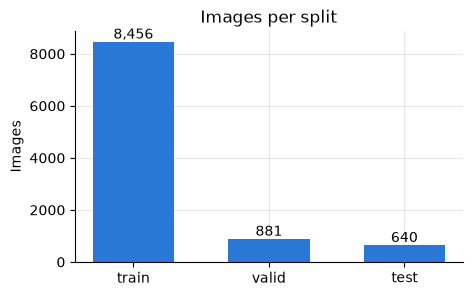

In [3]:
split_sizes = images["split"].value_counts().reindex(SPLITS)
print(split_sizes, "\n")
print((split_sizes / split_sizes.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(SPLITS, split_sizes, color="#2a78d6", width=0.6)
for i, n in enumerate(split_sizes):
    ax.text(i, n, f"{n:,}", ha="center", va="bottom")
ax.set_title("Images per split")
ax.set_ylabel("Images")
plt.show()

Roboflow made two copies of each training image (one flipped horizontally), so the
training images come from about half as many originals. Valid and test were not augmented.

## Instances per class

In [4]:
counts = boxes.pivot_table(index="class", columns="split", values="area",
                          aggfunc="count").reindex(CLASSES)[SPLITS]
counts["total"] = counts.sum(axis=1)
counts

split,train,valid,test,total
class,,,,
Fire,4622,417,305,5344
Lights,5235,502,407,6144
Smoke,5291,593,440,6324


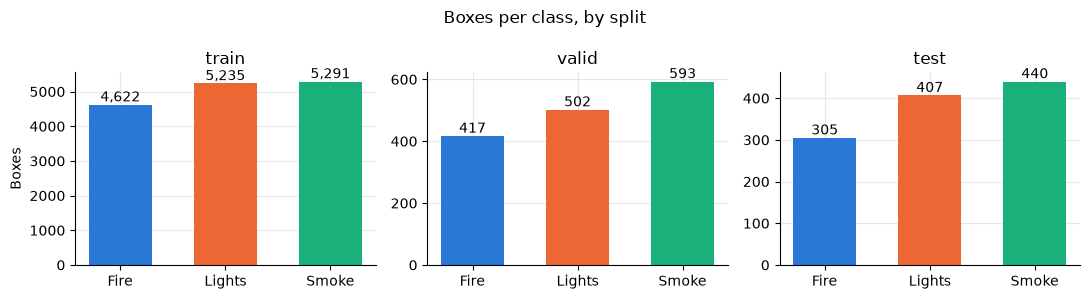

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=False)
for ax, split in zip(axes, SPLITS):
    ax.bar(CLASSES, counts[split], color=[COLORS[c] for c in CLASSES], width=0.6)
    for i, n in enumerate(counts[split]):
        ax.text(i, n, f"{n:,}", ha="center", va="bottom")
    ax.set_title(split)
axes[0].set_ylabel("Boxes")
fig.suptitle("Boxes per class, by split")
plt.tight_layout()
plt.show()

The classes are roughly balanced, and each class has 300-440 test boxes, which is enough
for a per-class AP that is stable to within a few points.

## Object size relative to the image

In [6]:
size = boxes.groupby("class")["area"].describe(percentiles=[0.25, 0.5, 0.75])
size["under_1pct"] = boxes.groupby("class")["area"].apply(lambda a: (a < 0.01).mean())
size["over_25pct"] = boxes.groupby("class")["area"].apply(lambda a: (a > 0.25).mean())
(size[["25%", "50%", "75%", "under_1pct", "over_25pct"]] * 100).round(1).rename(
    columns={"25%": "p25 %", "50%": "median %", "75%": "p75 %",
             "under_1pct": "boxes < 1% of image", "over_25pct": "boxes > 25% of image"})

,p25 %,median %,p75 %,boxes < 1% of image,boxes > 25% of image
class,,,,,
Fire,1.1,2.6,6.5,22.0,3.3
Lights,0.2,0.4,1.7,69.8,4.3
Smoke,2.3,9.5,21.4,11.2,20.2


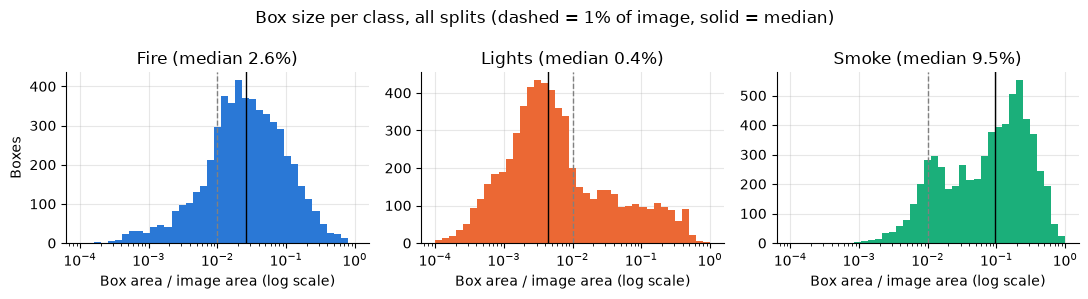

In [7]:
import numpy as np

bins = np.logspace(-4, 0, 40)
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharex=True)
for ax, cls in zip(axes, CLASSES):
    areas = boxes.loc[boxes["class"] == cls, "area"]
    ax.hist(areas, bins=bins, color=COLORS[cls])
    ax.axvline(0.01, color="gray", linestyle="--", linewidth=1)
    ax.axvline(areas.median(), color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{cls} (median {areas.median():.1%})")
    ax.set_xlabel("Box area / image area (log scale)")
axes[0].set_ylabel("Boxes")
fig.suptitle("Box size per class, all splits (dashed = 1% of image, solid = median)")
plt.tight_layout()
plt.show()

Lights are tiny (most boxes cover under 1% of the image), so a low Lights AP is expected
at 640 px. Smoke boxes are large with fuzzy edges, so Smoke will look worse under the
strict IoU thresholds of AP50-95 than under AP50.

## What the test images contain

classes
Fire or Smoke    512
Lights only      109
Empty             19
Name: count, dtype: int64 

classes
Fire or Smoke    0.80
Lights only      0.17
Empty            0.03
Name: count, dtype: float64


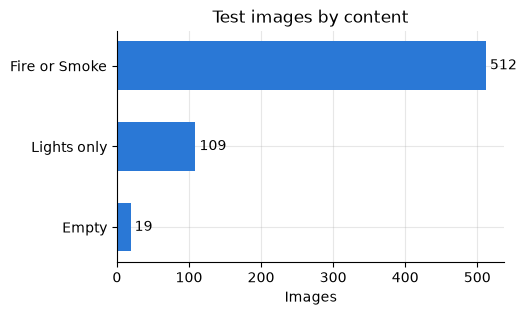

In [8]:
def content(classes):
    if classes & {"Fire", "Smoke"}:
        return "Fire or Smoke"
    if "Lights" in classes:
        return "Lights only"
    return "Empty"

test = images[images["split"] == "test"]
kinds = test["classes"].apply(content).value_counts().reindex(["Fire or Smoke", "Lights only", "Empty"])
print(kinds, "\n")
print((kinds / kinds.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(kinds.index[::-1], kinds.values[::-1], color="#2a78d6", height=0.6)
for i, n in enumerate(kinds.values[::-1]):
    ax.text(n, i, f" {n}", va="center")
ax.set_title("Test images by content")
ax.set_xlabel("Images")
plt.show()